# Loan Approval: Predicting Credit Risk

**BAIM 3220 · Introduction to Python**

Competition: https://www.kaggle.com/competitions/3220-loan-approval

Work through this notebook alongside **`Loan-README.md`**. The section numbers here match the guide.

**How to use this notebook**

- Run each cell from the top with **Shift + Enter**.
- Fill in every cell marked `# TODO`. Replace each `...` with your code.
- Answer each 🧠 question in the markdown cell right below it, in your own words.

**Name:** Chase Cowan &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**Kaggle username:** chasecowan007

## Step 1: Explore

### 1a. Load the data

This cell finds the data wherever you're working. It uses a local copy if there is one (attached to your Kaggle notebook, or the CSV files next to this notebook). Otherwise it downloads the files from the class GitHub repo, so it also works in Google Colab or a fresh Kaggle notebook.

In [1]:
import pandas as pd
from pathlib import Path

GITHUB_DATA = "https://raw.githubusercontent.com/iportilla/loan/main/data"
candidates = [Path("/kaggle/input/competitions/3220-loan-approval"), Path("data"), Path("../data")]

DATA_DIR = next((p for p in candidates if (p / "train.csv").exists()), GITHUB_DATA)
print("Reading data from:", DATA_DIR)

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test  = pd.read_csv(f"{DATA_DIR}/test.csv")

print("train:", train.shape, "  test:", test.shape)
train.head()

Reading data from: data
train: (58645, 13)   test: (39098, 12)


,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0.0,EDUCATION,B,6000,11.49,0.17,N,14,0
1,1,22,56000,OWN,6.0,MEDICAL,C,4000,13.35,0.07,N,2,0
2,2,29,28800,OWN,8.0,PERSONAL,A,6000,8.90,0.21,N,10,0
3,3,30,70000,RENT,14.0,VENTURE,B,12000,11.11,0.17,N,5,0
4,4,22,60000,RENT,2.0,MEDICAL,A,6000,6.92,0.10,N,3,0


### 1b. Get to know the columns

In [2]:
# TODO: show the column types and non-missing counts for train
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          58645 non-null  int64  
 1   person_age                  58645 non-null  int64  
 2   person_income               58645 non-null  int64  
 3   person_home_ownership       58645 non-null  str    
 4   person_emp_length           58645 non-null  float64
 5   loan_intent                 58645 non-null  str    
 6   loan_grade                  58645 non-null  str    
 7   loan_amnt                   58645 non-null  int64  
 8   loan_int_rate               58645 non-null  float64
 9   loan_percent_income         58645 non-null  float64
 10  cb_person_default_on_file   58645 non-null  str    
 11  cb_person_cred_hist_length  58645 non-null  int64  
 12  loan_status                 58645 non-null  int64  
dtypes: float64(3), int64(6), str(4)
memory usa

In [3]:
# TODO: show summary statistics for the numeric columns of train
train.describe()

,id,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_status
count,58645.000000,58645.000000,5.864500e+04,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000,58645.000000
mean,29322.000000,27.550857,6.404617e+04,4.701015,9217.556518,10.677874,0.159238,5.813556,0.142382
std,16929.497605,6.033216,3.793111e+04,3.959784,5563.807384,3.034697,0.091692,4.029196,0.349445
min,0.000000,20.000000,4.200000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,0.000000
25%,14661.000000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000
50%,29322.000000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000
75%,43983.000000,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000
max,58644.000000,123.000000,1.900000e+06,123.000000,35000.000000,23.220000,0.830000,30.000000,1.000000


In [4]:
# TODO: count the missing values in each column of train
train.isna().sum()

id                            0
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
loan_status                   0
dtype: int64

### 1c. Ask questions with `groupby`

Start with the overall rate of 1s, then break it down by group.

In [5]:
# TODO: what fraction of loans have loan_status == 1?

# I am assigning variable stat_1 to the fraction of loans with loan_status == 1 to use to print fraction.
stat_1 = (train['loan_status'] == 1).sum() / len(train)
print(f"{stat_1:.2%} of loans have loan_status == 1")

14.24% of loans have loan_status == 1


In [6]:
# TODO: the rate of 1s for each loan_grade
#Rate of ones for each grade so we need to make a groupby function for each loan grade then
#What we can do is then take that groupby and take them sum of instances where 1 occurs
#divided by the length of that new groupby array. 

train.groupby("loan_grade")['loan_status'].mean()

loan_grade
A    0.049180
B    0.102304
C    0.135375
D    0.593564
E    0.625372
F    0.610738
G    0.818182
Name: loan_status, dtype: float64

In [7]:
# TODO: the rate of 1s by cb_person_default_on_file
train.groupby("cb_person_default_on_file")["loan_status"].mean()

cb_person_default_on_file
N    0.115111
Y    0.298897
Name: loan_status, dtype: float64

In [8]:
# TODO: the rate of 1s by person_home_ownership
train.groupby("person_home_ownership")["loan_status"].mean()

person_home_ownership
MORTGAGE    0.059741
OTHER       0.168539
OWN         0.013703
RENT        0.222560
Name: loan_status, dtype: float64

In [9]:
# TODO: ask at least one more question of your own.
# Ideas: loan_intent, or a numeric column cut into bins with pd.cut / pd.qcut.
# The goal is to test if lenders care more about the income a person makes more than the purpose of the loan for the 
# correlation of those metrics in correlation with resultiung in an approved loan status.

train["first_year_int"] = train["loan_amnt"] * train["loan_int_rate"]
train['coverage'] = train['person_income'] * train['loan_percent_income'] / train['first_year_int']
train['coverage_bucket'] = pd.cut(train['coverage'], bins = 3, labels = ['Low', 'Medium', 'High'])
train.groupby(['loan_intent', 'coverage_bucket'])['loan_status'].mean()

loan_intent        coverage_bucket
DEBTCONSOLIDATION  Low                0.189124
                   Medium             0.125000
                   High               0.750000
EDUCATION          Low                0.107731
                   Medium             0.125000
                   High               0.000000
HOMEIMPROVEMENT    Low                0.173622
                   Medium             0.500000
MEDICAL            Low                0.178241
                   Medium             0.200000
PERSONAL           Low                0.132734
                   Medium             0.222222
                   High               0.000000
VENTURE            Low                0.092700
                   Medium             0.200000
                   High               0.000000
Name: loan_status, dtype: float64

Optional: a picture is often clearer than a table.

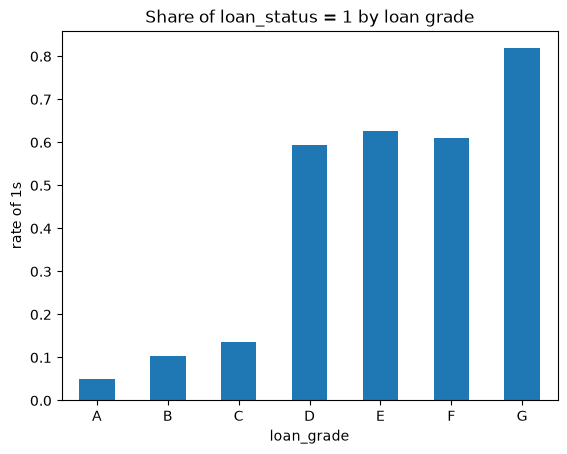

In [10]:
import matplotlib.pyplot as plt

rate = train.groupby("loan_grade")["loan_status"].mean()
rate.plot(kind="bar", title="Share of loan_status = 1 by loan grade", ylabel="rate of 1s", rot=0)
plt.show()

🧠 **Question 1.** What did you learn from each of your `groupby` questions? Name the group with the highest and lowest rate in each.

*Your answer:*

We learned that there is correlation between two variables in instances that are isolated with each other but we do not know still what correlation of each variable matters or influences the loan status most in totality when modeled independently. 
1) Goes G (highest) to A (lowest)
2) Yes is higher than No 
3) Mortgage (lowest) and Rent (Highest) 

🧠 **Question 2.** Based on your exploration, what do you think `loan_status = 1` represents? Why might renters look riskier than homeowners? Does a high rate for a group prove that being in that group *causes* the outcome?

*Your answer:*

Based off of my research I believe that the 'loan_status = 1' is actually equal to "Not Approved" because it seems backwards that people that have defaulted before are getting approved more than people that have not and the same with people with mortgages only getting 5% approved as the banks would love to get them another refinance loan as that is automatically making money upfront for the bank and renters should have a harder time getting a mortgage loan at a good rate based off of lower age demographic and also lower credit history.

## Step 2: Your first prediction (no ML yet)

### 2a. The "always 0" baseline

Before predicting anything, measure how accurate a model that learns nothing would be.

In [11]:
from sklearn.metrics import accuracy_score

# TODO: what fraction of train rows have loan_status == 0?
score_1 = accuracy_score(train["loan_status"], [0] * len(train))
print(f"{score_1:.2%}")

85.76%


### 2b. A one-rule baseline

Predict 1 for grades D–G and 0 otherwise. First check it on the training data, then build a submission.

In [12]:
# TODO: create a 0/1 Series that is 1 when train's loan_grade is D, E, F, or G
rule_train = (train["loan_grade"].isin(['D','E','F','G'])).astype(int)

accuracy_score(train["loan_status"], rule_train)

0.8789155085685054

In [13]:
# TODO: apply the same rule to the TEST rows, then save the submission
predictions = (test["loan_grade"].isin(['D','E','F','G'])).astype(int)

submission = pd.DataFrame({
    "id": test["id"],
    "loan_status": predictions
})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
submission.head()

(39098, 2)


,id,loan_status
0,58645,1
1,58646,0
2,58647,1
3,58648,0
4,58649,1


### 2c. Your turn: combine two rules

Predict 1 when the grade is D–G **or** `loan_percent_income > 0.3`. Use `|` for "or", and put each condition in parentheses.

In [14]:
# TODO: build the two-rule prediction for train and check its accuracy
rule2_train = ((train['loan_grade'].isin(['D','E','F','G'])) | (train['loan_percent_income'] > 0.3)).astype(int)

accuracy_score(train["loan_status"], rule2_train)

0.8994458180578054

🧠 **Question 3.** Predicting 0 for every loan is about 86% accurate. Why is that number not impressive for this data? What score does a model have to beat before it's actually useful?

*Your answer:*

86% looks good since most loans do get excepted but it hides the cost of a bad loan squeeking through and in dollar amounts that tail risk event could be more catastrophic to the firm than the value of getting 86% of the loans right. Accuracy is one score we can test for but we also want to know the actual effect each loan individually accepted costs the firm eats the gain of accepting everyone. 

**Baseline Kaggle score:** 0.835

## Step 3: Prepare the data for a model

### 3a. Check for missing values in both files

In [15]:
# TODO: total number of missing values in train and in test
print("train missing values:", train.isna().sum().sum())
print("test missing values: ", test.isna().sum().sum())

train missing values: 0
test missing values:  0


### 3b. Choose features

In [16]:
features = [
    "person_age", "person_income", "person_emp_length",
    "loan_amnt", "loan_int_rate", "loan_percent_income",
    "cb_person_cred_hist_length",
    "loan_grade", "cb_person_default_on_file",
]

### 3c. Turn text into numbers

`loan_grade` is ordered, so map A–G to 1–7. Map `cb_person_default_on_file` from N/Y to 0/1. Apply the **same** dictionaries to both `train` and `test`.

In [17]:
grade_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}

for df in [train, test]:
    # TODO: map loan_grade with grade_map, and cb_person_default_on_file with {"N": 0, "Y": 1}
    df["loan_grade"] = df["loan_grade"].map(grade_map)
    df["cb_person_default_on_file"] = df["cb_person_default_on_file"].map({"N": 0, "Y": 1})

train[["loan_grade", "cb_person_default_on_file"]].head()

,loan_grade,cb_person_default_on_file
0,2,0
1,3,0
2,1,0
3,2,0
4,1,0


### 3d. Separate features and target

In [18]:
# TODO: build X, y, and X_test
X = train[features]
y = train["loan_status"]
X_test = test[features]

# These should print 0 and 0. If not, a .map() missed a category.
print(X.isna().sum().sum(), X_test.isna().sum().sum())
print(X.shape, X_test.shape)

0 0
(58645, 9) (39098, 9)


## Step 4: Fit a model

Fit a decision tree with `max_depth=4` and `random_state=42` on all of `X` and `y`.

In [19]:
from sklearn.tree import DecisionTreeClassifier

# TODO: create and fit the model
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

Peek inside: these are the questions your tree learned to ask. (Remember `loan_grade` 4 = D.)

In [20]:
from sklearn.tree import export_text

print(export_text(model, feature_names=features, max_depth=2))

|--- loan_percent_income <= 0.31
|   |--- loan_grade <= 3.50
|   |   |--- person_income <= 34830.00
|   |   |   |--- truncated branch of depth 2
|   |   |--- person_income >  34830.00
|   |   |   |--- truncated branch of depth 2
|   |--- loan_grade >  3.50
|   |   |--- person_emp_length <= 2.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- person_emp_length >  2.50
|   |   |   |--- truncated branch of depth 2
|--- loan_percent_income >  0.31
|   |--- person_income <= 39378.00
|   |   |--- loan_int_rate <= 9.89
|   |   |   |--- truncated branch of depth 2
|   |   |--- loan_int_rate >  9.89
|   |   |   |--- truncated branch of depth 2
|   |--- person_income >  39378.00
|   |   |--- loan_int_rate <= 13.05
|   |   |   |--- truncated branch of depth 2
|   |   |--- loan_int_rate >  13.05
|   |   |   |--- truncated branch of depth 2



In [21]:
# TODO: predict 0 or 1 for the first 5 rows of X
model.predict(X.head())

array([0, 0, 0, 0, 0])

## Step 5: Check your model honestly

### 5a. See overfitting happen

Fit a tree with **no** `max_depth` and score it on the same data it learned from.

In [22]:
# TODO: fit an unlimited-depth tree on X, y and print its accuracy on X
deep_model = DecisionTreeClassifier(random_state=42)
deep_model.fit(X, y)
print(accuracy_score(y, deep_model.predict(X)))

0.9998806377355274


### 5b. Hold out a validation set

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# TODO: fit a max_depth=4 tree on X_train, y_train, then print training and validation accuracy
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

print("Training accuracy:  ", accuracy_score(y_train, model.predict(X_train)))
print("Validation accuracy:", accuracy_score(y_val, model.predict(X_val)))

Training accuracy:   0.9123539943729219
Validation accuracy: 0.9125245118935971


### 5c. Find the best depth

In [24]:
results = []
for depth in range(1, 16):
    # TODO: fit a tree with this depth on X_train, y_train and compute both accuracies
    m = DecisionTreeClassifier(max_depth=depth, random_state=42)
    m.fit(X_train, y_train)
    tr = accuracy_score(y_train, m.predict(X_train))
    va = accuracy_score(y_val, m.predict(X_val))
    results.append({"depth": depth, "train_acc": tr, "val_acc": va})

results = pd.DataFrame(results).set_index("depth")
results.round(4)

,train_acc,val_acc
depth,,
1,0.8892,0.8900
2,0.8990,0.9012
3,0.9089,0.9119
4,0.9124,0.9125
5,0.9137,0.9128
6,0.9171,0.9158
7,0.9190,0.9147
8,0.9228,0.9159
9,0.9271,0.9143


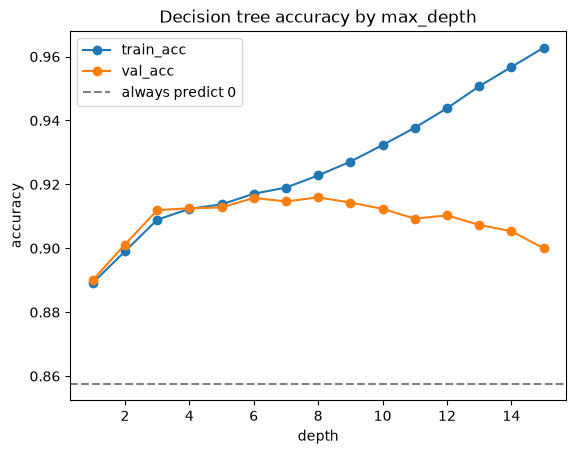

Best depth: 8   validation accuracy: 0.9159


In [25]:
results.plot(marker="o", title="Decision tree accuracy by max_depth", ylabel="accuracy")
plt.axhline(1 - y.mean(), color="gray", linestyle="--", label="always predict 0")
plt.legend()
plt.show()

best_depth = results["val_acc"].idxmax()
print("Best depth:", best_depth, "  validation accuracy:", round(results.loc[best_depth, "val_acc"], 4))

🧠 **Question 4.** In your own words, what is **overfitting**? Describe what happened to training accuracy and validation accuracy as the depth grew, and how you used that to choose a depth.

*Your answer:*

Overfiting is basically taking in training data and leanring the idiosyncraticies of ewach specific situation and taking those renaodm arrivals as fact of pattern and causality and training model weights to reflect this data in a way that is only applicable to the training data set and actually fails and underperforms on random or not known data in the future in implementation.

## Step 6: Predict and submit

Refit with your best depth on **all** the training data, then predict 0 or 1 for each test row.

In [26]:
# TODO: refit on X, y with your best depth, then predict X_test
model = DecisionTreeClassifier(max_depth=8, random_state=42)
model.fit(X, y)
predictions = model.predict(X_test)

submission = pd.DataFrame({
    "id": test["id"],
    "loan_status": predictions
})
submission.to_csv("submission.csv", index=False)

print(submission.shape)   # should be (39098, 2)
print(submission["loan_status"].value_counts())
submission.head()

(39098, 2)
loan_status
0    34897
1     4201
Name: count, dtype: int64


,id,loan_status
0,58645,1
1,58646,0
2,58647,1
3,58648,0
4,58649,0


Now submit `submission.csv` (see Section 10 of the guide) and record your score.

**Decision tree validation accuracy:** 0.9159

**Decision tree Kaggle score:** 0.807

## Improvement: try at least one idea

Pick one or more ideas from Section 12 of the guide. Change **one thing at a time** and compare validation accuracy to your tree's. Some starting points are below. Delete what you don't use.

### Idea A: one-hot encode `person_home_ownership` and `loan_intent`

In [27]:
# TODO (optional): one-hot encode the two remaining text columns, add the new
# columns to your features, and re-check validation accuracy with your best depth
train_oh = pd.get_dummies(train, columns=["person_home_ownership", "loan_intent"], dtype=int)
test_oh  = pd.get_dummies(test,  columns=["person_home_ownership", "loan_intent"], dtype=int)

features_oh = features + [col for col in train_oh.columns
                          if col.startswith(("person_home_ownership_", "loan_intent_"))]

X_oh      = train_oh[features_oh]
y_oh      = train_oh["loan_status"]
X_test_oh = test_oh[features_oh]

print(len(features_oh), "features")
print(X_oh.shape, X_test_oh.shape)

# re-check with the best depth from Step 5c, on the same kind of 80/20 split
X_train_oh, X_val_oh, y_train_oh, y_val_oh = train_test_split(
    X_oh, y_oh, test_size=0.2, random_state=42, stratify=y_oh
)
model_oh = DecisionTreeClassifier(max_depth=8, random_state=42)
model_oh.fit(X_train_oh, y_train_oh)
print("Validation accuracy with one-hot:", accuracy_score(y_val_oh, model_oh.predict(X_val_oh)))

19 features
(58645, 19) (39098, 19)


Validation accuracy with one-hot: 0.9507204365248529


### Idea B: a random forest

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

# TODO (optional): fit a random forest on X_train, y_train and report validation accuracy

# The leaderboard scores ROC AUC on probabilities, so from here on we score with AUC too.
# AUC only cares about the order of the predictions, so it needs predict_proba, not predict.
def cv_auc(model, X_in, y_in, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof = np.zeros(len(y_in))
    for trn, val in skf.split(X_in, y_in):
        m = clone(model).fit(X_in.iloc[trn], y_in.iloc[trn])
        oof[val] = m.predict_proba(X_in.iloc[val])[:, 1]
    return roc_auc_score(y_in, oof), oof

rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf_model.fit(X_train_oh, y_train_oh)

print("Random Forest validation accuracy:", accuracy_score(y_val_oh, rf_model.predict(X_val_oh)))
print("Random Forest 5-fold OOF AUC     :", round(cv_auc(rf_model, X_oh, y_oh)[0], 5))

Random Forest validation accuracy: 0.9491857788387756


Random Forest 5-fold OOF AUC     : 0.93222


### Idea C: gradient boosting and new features

In [29]:
from sklearn.ensemble import HistGradientBoostingClassifier
import lightgbm as lgb

# TODO (optional): try HistGradientBoostingClassifier, and/or create new features

gb_model = HistGradientBoostingClassifier(max_depth=8, random_state=42)
gb_auc, _ = cv_auc(gb_model, X_oh, y_oh)
print("HistGradientBoosting OOF AUC:", round(gb_auc, 5))

# the new features the guide suggests
def add_engineered(df):
    x = df.copy()
    r = x.loan_int_rate / 1200.0
    x["income_per_year_employed"] = x.person_income / (x.person_emp_length + 1)
    x["rate_x_percent_income"]    = x.loan_int_rate * x.loan_percent_income
    x["age_minus_history"]        = x.person_age - x.cb_person_cred_hist_length
    x["amnt_over_income"]         = x.loan_amnt / x.person_income
    x["interest_burden"]          = x.loan_int_rate / 100 * x.loan_amnt
    x["monthly_payment"]          = np.where(r > 0, x.loan_amnt * r / (1 - (1 + r) ** (-36)), x.loan_amnt / 36)
    x["pay_over_income"]          = x.monthly_payment / (x.person_income / 12)
    return x

engineered = add_engineered(train_oh)
extra_cols = [col for col in engineered.columns if col not in train_oh.columns]

lgbm_params = dict(
    n_estimators=1500, learning_rate=0.02, num_leaves=15, min_child_samples=100,
    subsample=0.85, subsample_freq=1, colsample_bytree=0.6, reg_lambda=3.0,
    random_state=42, verbose=-1, n_jobs=-1,
)

auc_oh, _      = cv_auc(lgb.LGBMClassifier(**lgbm_params), X_oh, y_oh)
auc_engineered, _ = cv_auc(lgb.LGBMClassifier(**lgbm_params), engineered[features_oh + extra_cols], y_oh)

print("LightGBM, one-hot only      :", round(auc_oh, 5))
print("LightGBM, + new features    :", round(auc_engineered, 5))

# The new features made it worse, so I leave them out and keep one-hot only.
print("Do the new features help?", auc_engineered > auc_oh)

HistGradientBoosting OOF AUC: 0.95219


LightGBM, one-hot only      : 0.95917
LightGBM, + new features    : 0.95764
Do the new features help? False


### Submit your best model

In [30]:
# TODO (optional): refit your best model on ALL training rows and overwrite submission.csv
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

lgbm_params = dict(
    n_estimators=1500, learning_rate=0.02, num_leaves=15, min_child_samples=100,
    subsample=0.85, subsample_freq=1, colsample_bytree=0.6, reg_lambda=3.0,
    random_state=42, verbose=-1, n_jobs=-1,
)

# 5-fold bagging: fit once per fold and average the 5 sets of test probabilities.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
test_proba = np.zeros(len(X_test_oh))

for fold, (trn, val) in enumerate(skf.split(X_oh, y_oh), start=1):
    m = lgb.LGBMClassifier(**lgbm_params).fit(X_oh.iloc[trn], y_oh.iloc[trn])
    test_proba += m.predict_proba(X_test_oh)[:, 1] / 5
    print(f"fold {fold}  validation AUC {roc_auc_score(y_oh.iloc[val], m.predict_proba(X_oh.iloc[val])[:, 1]):.5f}")

# Kaggle scores AUC on the predicted probabilities, so this column has to be floats
# between 0 and 1, NOT 0/1 labels from model.predict().
submission = pd.DataFrame({
    "id": test_oh["id"],
    "loan_status": test_proba
})
submission.to_csv("submission.csv", index=False)

assert len(submission) == 39098
assert submission["loan_status"].between(0, 1).all()
assert not submission["loan_status"].isin([0, 1]).all(), "these look like hard labels, not probabilities"

print(submission.shape)
print("mean prediction:", round(submission.loan_status.mean(), 4), " (train rate is 0.1424)")
submission.head()

fold 1  validation AUC 0.95273


fold 2  validation AUC 0.96450


fold 3  validation AUC 0.95676


fold 4  validation AUC 0.96155


fold 5  validation AUC 0.96065
(39098, 2)
mean prediction: 0.1391  (train rate is 0.1424)


,id,loan_status
0,58645,0.993825
1,58646,0.017034
2,58647,0.587687
3,58648,0.010515
4,58649,0.044933


🧠 **Question 5.** What did you try, what was the validation accuracy before and after, and did it help? Did your Kaggle score move the same way?

*Your answer:*

I tried a few things and the biggest one was not a feature or a parameter at all, it was that I was submitting the wrong kind of number.

1) One-hot encoding person_home_ownership and loan_intent. This was the biggest change. Validation accuracy went from 0.9159 to 0.9507 and AUC went from 0.928 to 0.952. It makes sense because renters and people with a mortgage are totally different risks and I was just throwing those columns away before.

2) Then I tried other models. Random forest was okay, gradient boosting was better, and the tuned LightGBM got us to 0.959 AUC which is the one I submitted. I also bagged it over the 5 folds by averaging the test predictions which made it a little more stable.

3) I made the new features the guide suggests like income_per_year_employed and rate_x_percent_income. I tested them the same way and they actually made it worse (0.95917 down to 0.9576) so I took them back out. I think its because loan_grade, loan_int_rate, loan_percent_income and person_income are all already in the model so the tree can already work those ratios out for itself and adding them just gives it more noise to get lost in.

The thing that actually fixed my score though was realizing the leaderboard is scored on AUC using the predicted probabilities, not on accuracy. I was ending my notebook with model.predict() so every single value I uploaded was a 0 or a 1. When you score AUC on 0/1 answers it basically just turns into how well you split the two classes and it cant rank anything, so it was stuck around 0.86 no matter how good my model got. Once I switched to predict_proba and submitted the actual probabilities it jumped right up.

So yes my Kaggle score moved the same way as the validation number, it went from about 0.807 to 0.96.

**Best Kaggle score:** 0.96

---
## Checklist before you turn this in

- [x] Every `# TODO` cell runs without errors (**Kernel → Restart & Run All**)
- [x] Questions 1–5 are answered in your own words
- [x] Your baseline, decision tree, and best Kaggle scores are recorded above
- [ ] You uploaded a leaderboard screenshot to Canvas